# Experiment 3 — MovieLens: real rating distributions

Figures per `docs/experiments.md`, Experiment 3 “Figures” subsection. This notebook only loads `results/exp3/results.parquet` and plots — it never recomputes algorithm results (see CLAUDE.md and `docs/experiments.md` §0.4). Run `make exp3` (or `make smoke`) first if that file is missing.

Reconstructing `MovieLensEnv` below (for the prototype titles/histograms in Figure 1) is *not* a recompute of algorithm results — prototype selection is a deterministic, scripted function of `data/ml-1m/` (`docs/experiments.md`: "notebooks/03 shows the result"), independent of any algorithm run.

**Note:** as of this run, `results/exp3/` holds `SMOKE_TEST` output (reduced K/reps) — figures are structurally correct but not the paper's real grid/rep counts.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, style_for, legend_for_algorithms, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS
from kabc.environments import MovieLensEnv

set_style()

RESULTS_PATH = Path("../results/exp3/results.parquet")
if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"{RESULTS_PATH} not found. Run `make exp3` (or `make smoke`) to generate it — "
        "this notebook only plots existing results, it never recomputes them."
    )
df = pd.read_parquet(RESULTS_PATH)
print(f"loaded {len(df)} rows from {RESULTS_PATH}")

main_df = df[df["family"] == "movielens"].copy()
reduced_df = df[df["family"] == "movielens_reduced"].copy()
df.head()

loaded 30 rows from ../results/exp3/results.parquet


,exp_id,family,algorithm,rep,seed,swept_param,swept_value,budget_cap,s_star,tau,...,Delta,sigma,sigma_B,a,ring_radius,ring_noise,data_dir,arms_per_prototype,min_ratings,mean_gap_tol
0,3,movielens,kabc,0,3000,None,None,10000,None,6140,...,None,None,None,None,None,None,data/ml-1m,2,1000,0.05
1,3,movielens,kabc,1,3001,None,None,10000,None,6140,...,None,None,None,None,None,None,data/ml-1m,2,1000,0.05
2,3,movielens,kabc,2,3002,None,None,10000,None,6140,...,None,None,None,None,None,None,data/ml-1m,2,1000,0.05
3,3,movielens,kabc,3,3003,None,None,10000,None,6140,...,None,None,None,None,None,None,data/ml-1m,2,1000,0.05
4,3,movielens,kabc,4,3004,None,None,10000,None,6140,...,None,None,None,None,None,None,data/ml-1m,2,1000,0.05


## Figure 1 (headline): same-mean prototype pair histograms + ARI vs budget

Left: rating histograms of the polarizing-vs-consensus prototype pair (the one with `|mean gap| <= mean_gap_tol` maximizing MMD², per `docs/experiments.md` Experiment 3 step 2), reconstructed deterministically from `data/ml-1m/` via `MovieLensEnv`. Right: ARI vs budget from the stored results — ACB is expected to plateau below 1, KABC to reach 1 and stop (τ marked).

In [2]:
# Reconstruct the deterministic prototype selection using the same base
# kwargs as configs/exp3.yaml's `movielens` family, to identify and plot the
# same-mean pair -- no algorithm/bandit logic is run here.
env = MovieLensEnv(
    data_dir="../data/ml-1m", K=4, arms_per_prototype=10, min_ratings=1000, mean_gap_tol=0.05
)
means = [pool.mean() for pool in env.prototype_pools]
pairs = [(i, j) for i in range(len(means)) for j in range(i + 1, len(means))]
same_mean_pair = min(pairs, key=lambda p: abs(means[p[0]] - means[p[1]]))
i1, i2 = same_mean_pair
print(f"same-mean pair: {env.prototype_titles[i1]!r} (mean={means[i1]:.2f}) vs "
      f"{env.prototype_titles[i2]!r} (mean={means[i2]:.2f})")

same-mean pair: 'Clear and Present Danger (1994)' (mean=3.73) vs 'South Park: Bigger, Longer and Uncut (1999)' (mean=3.76)


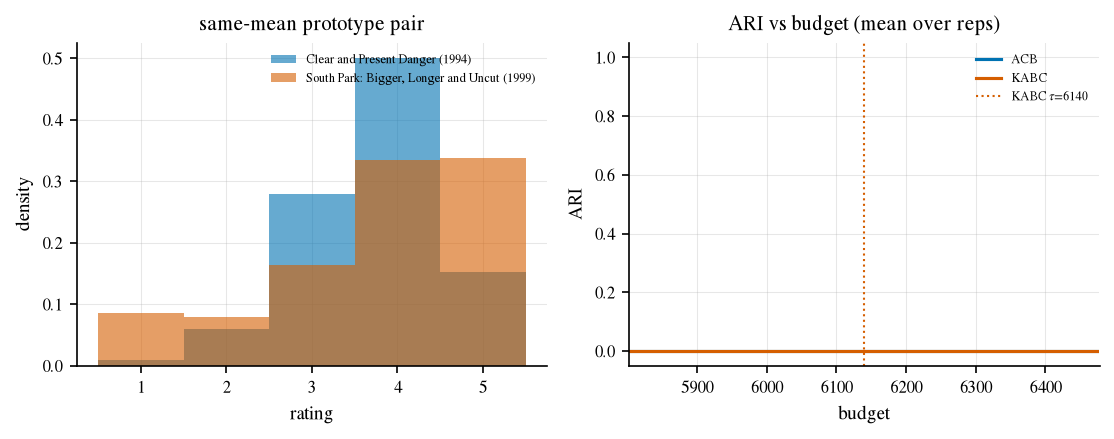

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))

ax = axes[0]
bins = np.arange(0.5, 6.5, 1.0)
ax.hist(env.prototype_pools[i1], bins=bins, density=True, alpha=0.6,
        label=env.prototype_titles[i1], color="#0072B2")
ax.hist(env.prototype_pools[i2], bins=bins, density=True, alpha=0.6,
        label=env.prototype_titles[i2], color="#D55E00")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("rating")
ax.set_ylabel("density")
ax.set_title("same-mean prototype pair")
ax.legend(fontsize=6, frameon=False)

ax = axes[1]
for algo in [a for a in ["acb", "kabc"] if a in main_df["algorithm"].unique()]:
    sub = main_df[main_df["algorithm"] == algo]
    mean_ari = sub["ari"].mean()
    mean_tau = sub["tau"].mean()
    ax.axhline(mean_ari, **{**style_for(algo), "marker": None})
    if algo == "kabc":
        ax.axvline(mean_tau, color=ALGO_COLORS["kabc"], linestyle=":", linewidth=1,
                    label=rf"KABC $\tau$={mean_tau:.0f}")
ax.set_xlabel("budget")
ax.set_ylabel("ARI")
ax.set_ylim(-0.05, 1.05)
ax.set_title("ARI vs budget (mean over reps)")
ax.legend(fontsize=6, frameon=False)

fig.tight_layout()
savefig(fig, "exp3_fig1_same_mean_pair_and_ari", fig_dir="../results/figures")
plt.show()

## Figure 2: τ and error (kabc/kabc-sg), ARI-at-cap (acb)

In [4]:
rows = []
for algo in [a for a in ALGO_ORDER if a in main_df["algorithm"].unique()]:
    sub = main_df[main_df["algorithm"] == algo]
    rows.append({
        "algorithm": ALGO_LABELS[algo],
        "mean_tau": sub["tau"].mean(),
        "mean_error": sub["error"].mean(),
        "mean_ari": sub["ari"].mean(),
        "frac_stopped": sub["stopped"].mean(),
    })
fig2_table = pd.DataFrame(rows)
fig2_table

,algorithm,mean_tau,mean_error,mean_ari,frac_stopped
0,KABC,6140.0,1.0,0.0,0.0
1,KABC-SG,6140.0,0.0,1.0,1.0
2,ACB,9996.4,1.0,0.0,0.0
3,Unif-KKM,10000.0,0.0,1.0,1.0


## Figure 3: small-instance table — tas-fw vs kabc on the N=6 reduced instance

In [5]:
rows = []
for algo in [a for a in ["tas-fw", "kabc"] if a in reduced_df["algorithm"].unique()]:
    sub = reduced_df[reduced_df["algorithm"] == algo]
    rows.append({
        "algorithm": ALGO_LABELS[algo],
        "mean_tau": sub["tau"].mean(),
        "mean_error": sub["error"].mean(),
        "mean_ari": sub["ari"].mean(),
        "mean_wall_clock_s": sub["wall_clock_seconds"].mean(),
    })
fig3_table = pd.DataFrame(rows)
fig3_table

,algorithm,mean_tau,mean_error,mean_ari,mean_wall_clock_s
0,TaS-FW,2597.8,0.0,1.0,6.870824
1,KABC,6140.0,1.0,0.0,0.725474
